In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from ipynb.fs.full.preprocessing import process_the_data, read_the_data

<h3> Looking at the steps calculated by DeltabotController

In [3]:
mesh0045_27Oct = pd.read_csv("processed_data/27Oct_0045_mesh.csv")

We can see that the snaking behaviour of the steps

In [4]:
# algorithm_steps
print("Calculated Motor Values Max/Min")
print(max(mesh0045_27Oct["s0"]))
print(max(mesh0045_27Oct["s1"]))
print(max(mesh0045_27Oct["s2"]))
print(min(mesh0045_27Oct["s0"]))
print(min(mesh0045_27Oct["s1"]))
print(min(mesh0045_27Oct["s2"]))

Calculated Motor Values Max/Min
6144.0
8393.0
8393.0
-6144.0
-8393.0
-8393.0


<h3> Looking at the steps predicted by the MLP

In [5]:
#gave those x and y values to the 16Oct MLP 
#output
pred_snake_steps = pd.read_csv("predictions/16Oct_MLP_2_Pred_snake_mesh.csv", names=["s0", "s1", "s2"])
display(pred_snake_steps.head())
print("Predicted motor values Max/Min")
print(max(pred_snake_steps["s0"]))
print(max(pred_snake_steps["s1"]))
print(max(pred_snake_steps["s2"]))
print(min(pred_snake_steps["s0"]))
print(min(pred_snake_steps["s1"]))
print(min(pred_snake_steps["s2"]))

,s0,s1,s2
0,4722.502930,-5562.666016,921.905762
1,4755.381836,-5359.010742,657.899109
2,4803.966797,-5138.896973,384.330017
3,4866.707031,-4899.888184,112.023315
4,4868.121582,-4637.533691,-180.733459


Predicted motor values Max/Min
4868.12158203125
6600.51171875
5965.73291015625
-4499.62060546875
-5562.666015625
-5378.6142578125


In [7]:
pred_snake_steps['sum_motors'] = pred_snake_steps["s0"] + pred_snake_steps["s1"] + pred_snake_steps["s2"]
# display(pred_snake_steps['sum_motors'])
print(max(pred_snake_steps["sum_motors"]))
print(min(pred_snake_steps["sum_motors"]))


pred_snake_steps["s0_adj"] = pred_snake_steps["s0"] - (pred_snake_steps["sum_motors"]/3)
pred_snake_steps["s1_adj"] = pred_snake_steps["s1"] - (pred_snake_steps["sum_motors"]/3)
pred_snake_steps["s2_adj"] = pred_snake_steps["s2"] - (pred_snake_steps["sum_motors"]/3)

pred_snake_steps['sum_motors_adj'] = pred_snake_steps["s0_adj"] + pred_snake_steps["s1_adj"] + pred_snake_steps["s2_adj"]
# display(pred_snake_steps['sum_motors'])
print(max(pred_snake_steps["sum_motors_adj"]))
print(min(pred_snake_steps["sum_motors_adj"]))
print(max(pred_snake_steps["s0_adj"]))
print(max(pred_snake_steps["s1_adj"]))
print(max(pred_snake_steps["s2_adj"]))
print(min(pred_snake_steps["s0_adj"]))
print(min(pred_snake_steps["s1_adj"]))
print(min(pred_snake_steps["s2_adj"]))


116.27850341796875
-129.5185546875
9.094947017729282e-13
-9.094947017729282e-13
4851.503438313802
6618.036458333333
5984.461832682292
-4482.095865885417
-5589.91357421875
-5371.6304931640625


Quite high strain if 278 / 260 sum of the motors

Text(0.5, 0.98, 'Predictions from Standard Scaled MLP Snake Scan')

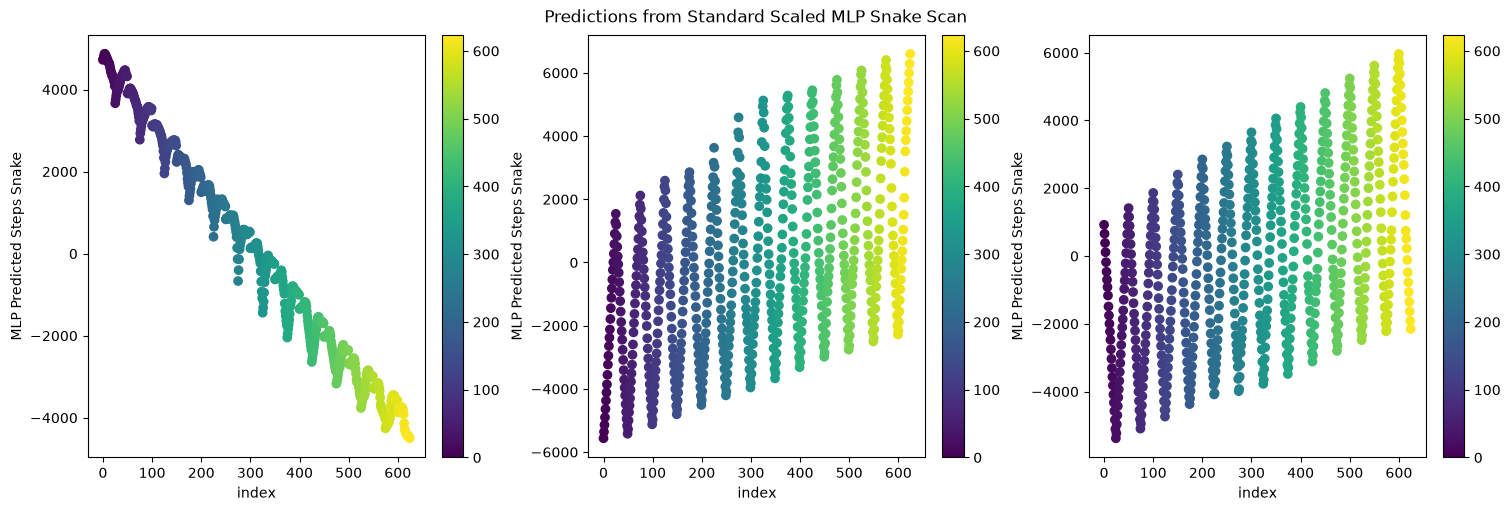

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)
for i, motor in enumerate(["s0", "s1", "s2"]):
    im = axs[i].scatter(pred_snake_steps[motor].index, pred_snake_steps[motor], c=pred_snake_steps.index)
    axs[i].set_xlabel("index")
    axs[i].set_ylabel("MLP Predicted Steps Snake")
    fig.colorbar(im, ax=axs[i])  
fig.suptitle("Predictions from Standard Scaled MLP Snake Scan")

Text(0.5, 0.98, 'Predictions from Standard Scaled MLP Snake Scan - motor values adjusted to sum to 0')

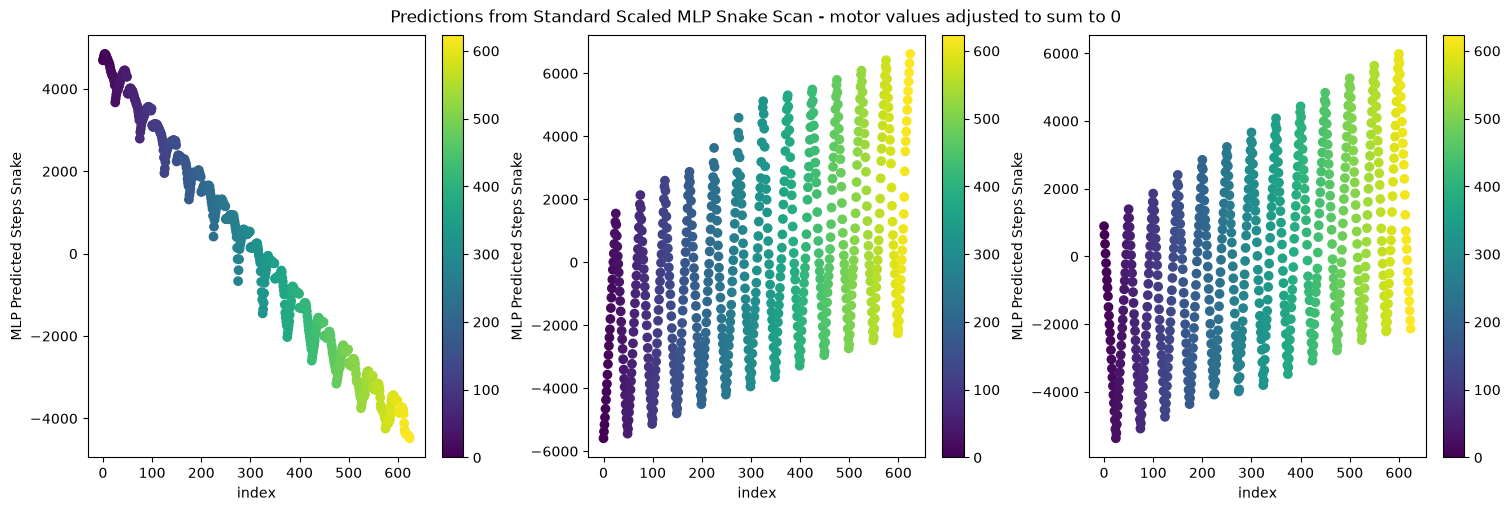

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)
for i, motor in enumerate(["s0_adj", "s1_adj", "s2_adj"]):
    im = axs[i].scatter(pred_snake_steps[motor].index, pred_snake_steps[motor], c=pred_snake_steps.index)
    axs[i].set_xlabel("index")
    axs[i].set_ylabel("MLP Predicted Steps Snake")
    fig.colorbar(im, ax=axs[i])
fig.suptitle("Predictions from Standard Scaled MLP Snake Scan - motor values adjusted to sum to 0")

<h2> Comparing the 2 datasets

Text(0.5, 0.98, 'DeltabotController Motor values vs Standard Scaled MLP Predictions for snake scan')

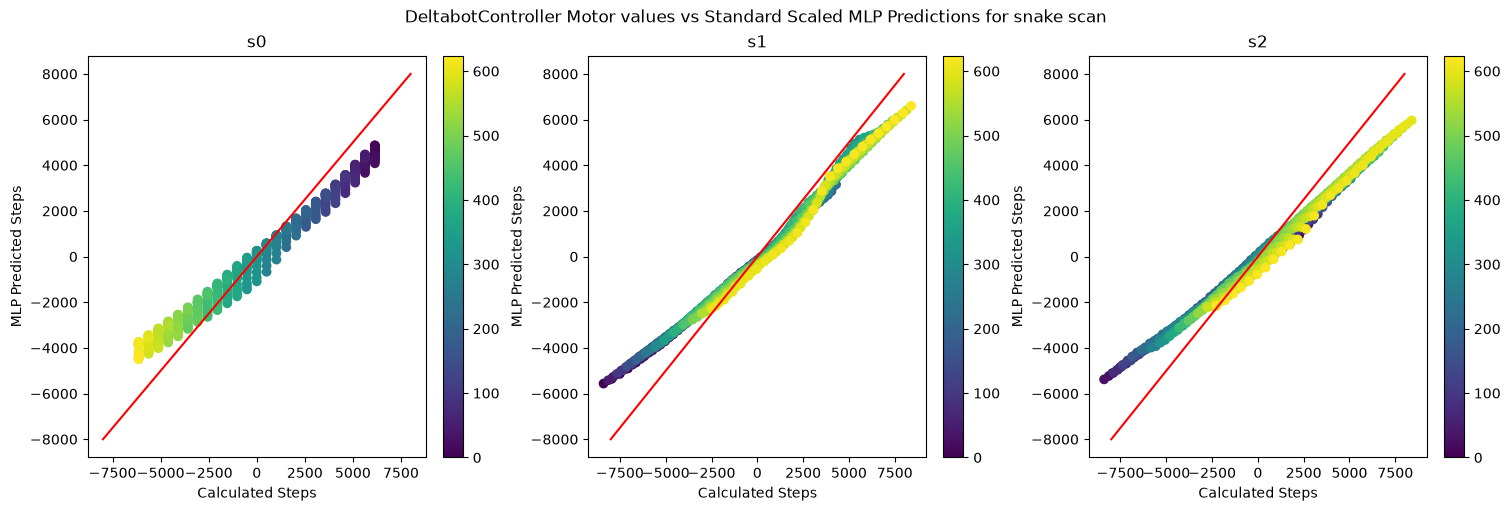

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)
for i, motor in enumerate(["s0", "s1", "s2"]):
    im = axs[i].scatter(mesh0045_27Oct[motor], pred_snake_steps[motor], c=mesh0045_27Oct["point"])
    axs[i].set_xlabel("Calculated Steps")
    axs[i].set_ylabel("MLP Predicted Steps")
    fig.colorbar(im, ax=axs[i])  
    axs[i].set_title(motor)
    lims = [-8000, 8000]
    # axs[i].set_xlim(lims)
    # axs[i].set_ylim(lims)
    _ = axs[i].plot(lims, lims, color="red")

fig.suptitle("DeltabotController Motor values vs Standard Scaled MLP Predictions for snake scan")

Text(0.5, 0.98, 'DeltabotController Motor values vs Standard Scaled MLP Predictions for snake scan - values adjusted to sum to 0')

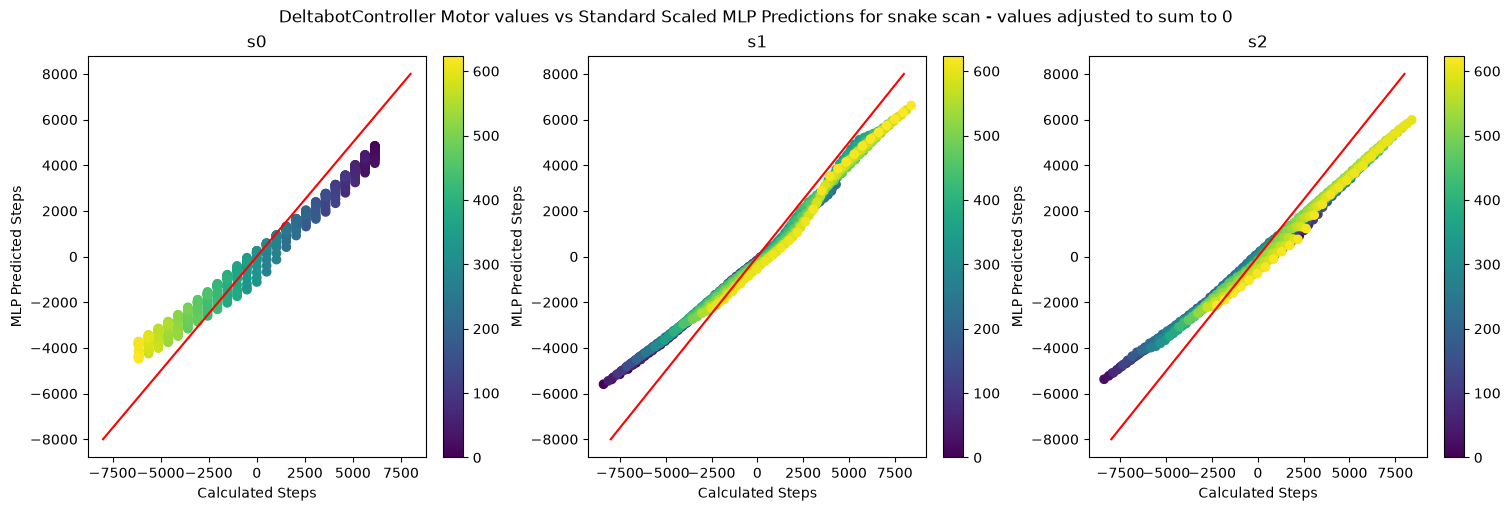

In [12]:
fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)
for i, motor in enumerate(["s0", "s1", "s2"]):
    im = axs[i].scatter(mesh0045_27Oct[motor], pred_snake_steps[f"{motor}_adj"], c=mesh0045_27Oct["point"])
    axs[i].set_xlabel("Calculated Steps")
    axs[i].set_ylabel("MLP Predicted Steps")
    fig.colorbar(im, ax=axs[i])  
    axs[i].set_title(motor)
    lims = [-8000, 8000]
    # axs[i].set_xlim(lims)
    # axs[i].set_ylim(lims)
    _ = axs[i].plot(lims, lims, color="red")

fig.suptitle("DeltabotController Motor values vs Standard Scaled MLP Predictions for snake scan - values adjusted to sum to 0")

In [32]:
pred_snake_steps[["s0_adj", "s1_adj", "s2_adj"]].astype("int32").to_csv("predictions/adjusted/16Oct_MLP_Scaled_snake.csv", index=False)

In [31]:
data = pd.read_csv("predictions/adjusted/16Oct_MLP_Scaled_snake.csv")
points = list(data.itertuples(index=False, name=None))
print(points)

[(0, 4695, -5589, 894), (1, 4737, -5377, 639), (2, 4787, -5155, 367), (3, 4840, -4926, 85), (4, 4851, -4654, -197), (5, 4836, -4371, -465), (6, 4814, -4114, -699), (7, 4786, -3864, -922), (8, 4741, -3566, -1175), (9, 4728, -3234, -1493), (10, 4692, -2944, -1747), (11, 4658, -2652, -2006), (12, 4634, -2390, -2244), (13, 4613, -2130, -2483), (14, 4562, -1799, -2762), (15, 4496, -1454, -3042), (16, 4436, -1123, -3313), (17, 4399, -828, -3571), (18, 4373, -547, -3826), (19, 4324, -237, -4087), (20, 4320, 7, -4327), (21, 4294, 279, -4573), (22, 4248, 582, -4831), (23, 4187, 915, -5102), (24, 4092, 1279, -5371), (25, 3673, 1548, -5222), (26, 3764, 1195, -4959), (27, 3855, 835, -4691), (28, 3923, 499, -4422), (29, 3974, 196, -4171), (30, 3983, -51, -3931), (31, 4006, -322, -3684), (32, 4049, -625, -3423), (33, 4087, -924, -3162), (34, 4136, -1228, -2907), (35, 4191, -1560, -2630), (36, 4245, -1890, -2354), (37, 4287, -2175, -2111), (38, 4310, -2445, -1865), (39, 4346, -2751, -1594), (40, 4369

In [38]:
# list(pred_snake_steps.itertuples(index=False, name=None))

<h1>Output from Scan using predicted motor values

In [33]:
path = "scripts/scans/MLP"
scan = "0009_MLP_16Oct"

x_conversion = 0.1/11
y_conversion = x_conversion

start_cx = 306 #px #scan 94
start_cy = 260 #px #scan 94

scan_MLP = process_the_data(scan, path, x_conversion, y_conversion, start_cx, start_cy)
scan_MLP.name = "scan_MLP"

In [ ]:
scan_MLP

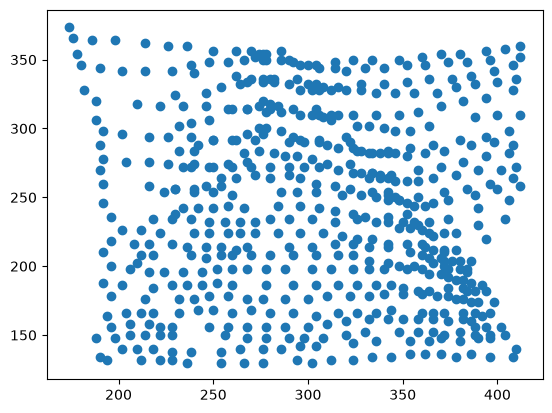

In [34]:
plt.scatter(scan_MLP["cx"], scan_MLP["cy"])

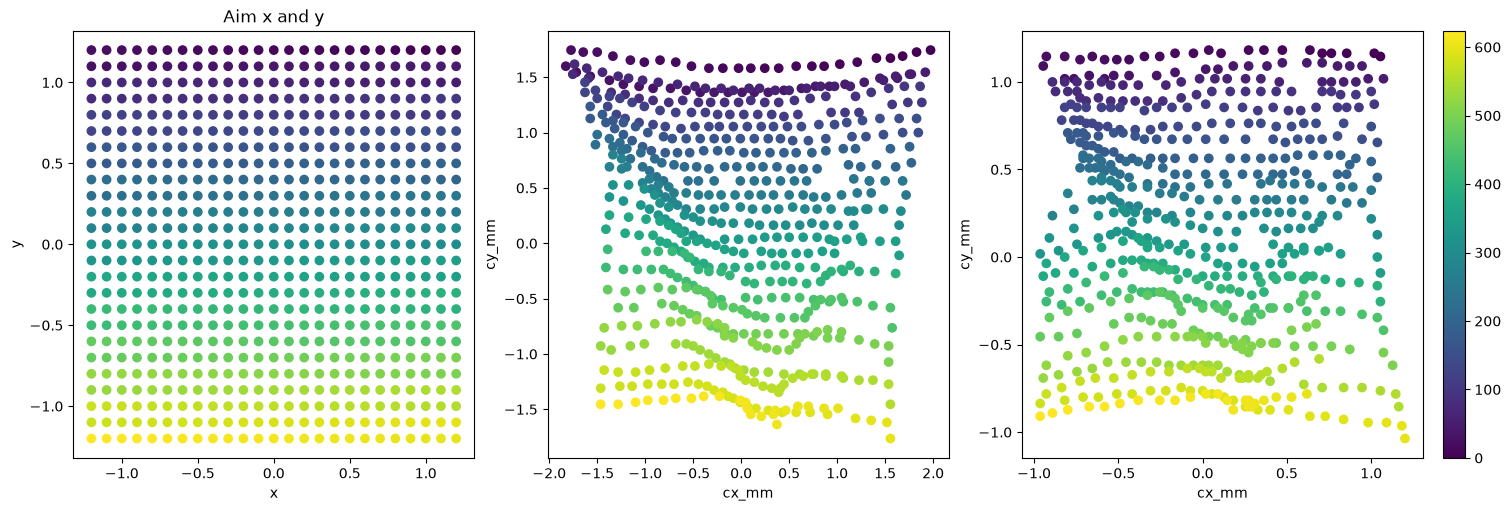

In [36]:
fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)

im = axs[0].scatter(mesh0045_27Oct["x"], mesh0045_27Oct["y"], c=mesh0045_27Oct["point"])
axs[0].set_xlabel("x")
axs[0].set_ylabel("y")
axs[0].set_title("Aim x and y")

i = 1
for scan in mesh0045_27Oct, scan_MLP:
    suplot = axs[i]
    suplot.scatter(scan["cx_mm"], scan["cy_mm"], c=scan["point"])
    suplot.set_xlabel("cx_mm")
    suplot.set_ylabel("cy_mm")
    # fig.colorbar(im, ax=axs[i])  
    # suplot.set_title(scan.name)
    i = i+1

fig.colorbar(im, ax=axs[2])  